<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/01_weather_download.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd          # for working with tables of data
import requests              # for downloading data from the internet
import matplotlib.pyplot as plt   # for charts

In [2]:
# Coordinates of the US consulate monitor area (Baridhara, Dhaka)
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 23.80,
    "longitude": 90.42,
    "start_date": "2016-01-01",
    "end_date": "2025-12-31",
    "hourly": "temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m",
    "timezone": "Asia/Dhaka",   # so times match Dhaka clock time
}
response = requests.get(url, params=params)
data = response.json()
print("Downloaded", len(data["hourly"]["time"]), "hours of weather")

Downloaded 87672 hours of weather


In [3]:
weather = pd.DataFrame(data["hourly"])
weather["time"] = pd.to_datetime(weather["time"])
weather.head(10)

,time,temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m,wind_direction_10m
0,2016-01-01 00:00:00,16.1,90,0.0,9.7,318
1,2016-01-01 01:00:00,15.4,91,0.0,8.9,328
2,2016-01-01 02:00:00,14.9,92,0.0,8.5,332
3,2016-01-01 03:00:00,14.5,93,0.0,8.9,333
4,2016-01-01 04:00:00,14.1,94,0.0,8.1,328
5,2016-01-01 05:00:00,13.8,95,0.0,8.4,335
6,2016-01-01 06:00:00,13.7,95,0.0,7.1,330
7,2016-01-01 07:00:00,13.5,96,0.0,6.4,333
8,2016-01-01 08:00:00,15.9,93,0.0,3.3,347
9,2016-01-01 09:00:00,19.9,76,0.0,2.2,9


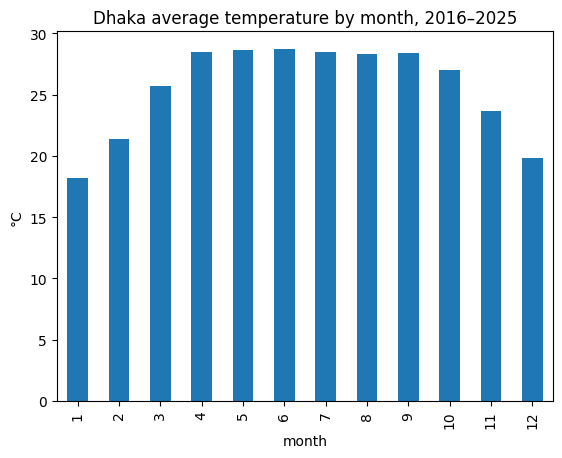

In [4]:
weather["month"] = weather["time"].dt.month
weather.groupby("month")["temperature_2m"].mean().plot(kind="bar")
plt.title("Dhaka average temperature by month, 2016–2025")
plt.ylabel("°C")
plt.show()

In [5]:
weather.to_csv("dhaka_weather_2016_2025.csv", index=False)